# COS40007 – Applied Project Task 1: Quick EDA
**Dataset:** AI4I 2020 Predictive Maintenance Dataset (Matzka, 2020)  
**Goal:** understand the data and collect insights that justify the system design (preprocessing, features, metrics, monitoring).

Put `ai4i2020.csv` in the same folder as this notebook (or upload it when running on Colab). All figures are saved to `figures/` for the report.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [2]:
# On Google Colab, uncomment the two lines below to upload the CSV
# from google.colab import files
# files.upload()

df = pd.read_csv("ai4i2020.csv")
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 1. Overview: size, types, missing values, duplicates

In [3]:
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing values per column:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Unique UDI:", df["UDI"].nunique(), "| Unique Product ID:", df["Product ID"].nunique())

Shape: (10000, 14)

Data types:
UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

Missing values per column:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Duplicate rows: 

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


**📝 Observation:**

- The dataset has 10,000 rows and 14 columns, with no missing values and no duplicate rows, so no imputation is needed.
- UDI and Product ID are unique for every row (10,000 unique values each). They are only identifiers, so we will drop them before training.
- The six input features are Type (categorical) and five numeric sensor/process readings with very different scales (e.g. temperature around 300 K vs rotational speed around 1,500 rpm).

## 2. Target: how often do machines fail?
This decides whether the classes are balanced and which metric we should use.

Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure rate: 3.39%  (339 of 10000 records)


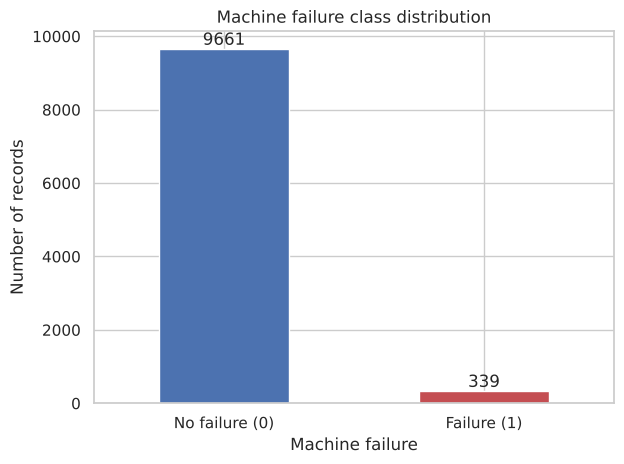

In [5]:
counts = df["Machine failure"].value_counts().sort_index()
rate = df["Machine failure"].mean()
print(counts)
print(f"\nFailure rate: {rate:.2%}  ({counts.get(1, 0)} of {len(df)} records)")

ax = counts.plot(kind="bar", color=["#4C72B0", "#C44E52"])
ax.set_xticklabels(["No failure (0)", "Failure (1)"], rotation=0)
ax.set_ylabel("Number of records")
ax.set_title("Machine failure class distribution")
for i, v in enumerate(counts):
    ax.text(i, v, str(v), ha="center", va="bottom")
save("01_target_distribution")

**📝 Observation:**

- Only 339 of 10,000 records (3.39%) are failures, so the dataset is highly imbalanced.
- A model that always predicts "no failure" would already reach about 96.6% accuracy, so accuracy is misleading here.
- We will use Recall and F1 as the main metrics, use a stratified train/validation/test split, and handle imbalance with class weights or SMOTE (on the training set only).

## 3. Failure modes: TWF, HDF, PWF, OSF, RNF
Check how often each mode occurs, and whether the mode columns agree with `Machine failure` (they would cause **data leakage** if used as inputs).

HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64


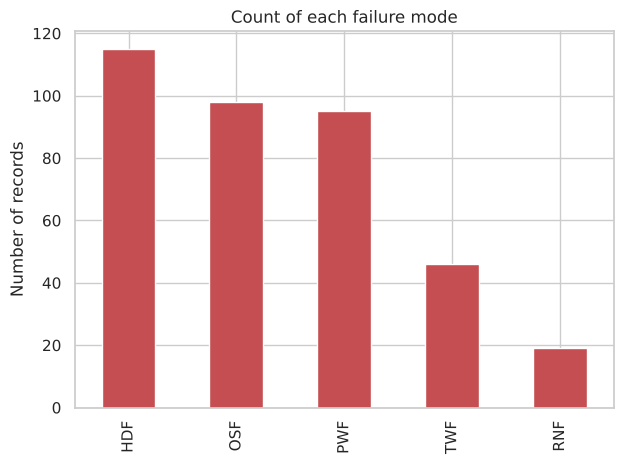

In [6]:
modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]
mode_counts = df[modes].sum().sort_values(ascending=False)
print(mode_counts)

ax = mode_counts.plot(kind="bar", color="#C44E52")
ax.set_ylabel("Number of records")
ax.set_title("Count of each failure mode")
save("02_failure_modes")

In [7]:
any_mode = df[modes].sum(axis=1) > 0
print("Failures with no failure mode flagged:", ((df["Machine failure"] == 1) & ~any_mode).sum())
print("Failure mode flagged but Machine failure = 0:", ((df["Machine failure"] == 0) & any_mode).sum())
print("Records with more than one failure mode:", (df[modes].sum(axis=1) > 1).sum())

Failures with no failure mode flagged: 9
Failure mode flagged but Machine failure = 0: 18
Records with more than one failure mode: 24


**📝 Observation:**

- HDF is the most common failure mode (115), followed by OSF (98) and PWF (95); TWF (46) and RNF (19) are rare.
- The labels are not fully consistent: 9 failures have no failure mode flagged, and 18 records have RNF = 1 but Machine failure = 0. Also, 24 records have more than one failure mode.
- Because these columns directly define the target, using them as inputs would cause data leakage. We will drop them for the main model and only use them as labels for the secondary failure-type task (records with several modes need a rule, e.g. multi-label or keep the first mode).

## 4. Product Type (L / M / H)

Share of records by Type:
 Type
L    0.6
M    0.3
H    0.1
Name: proportion, dtype: float64

Failure rate by Type:
 Type
H    0.0209
L    0.0392
M    0.0277
Name: Machine failure, dtype: float64


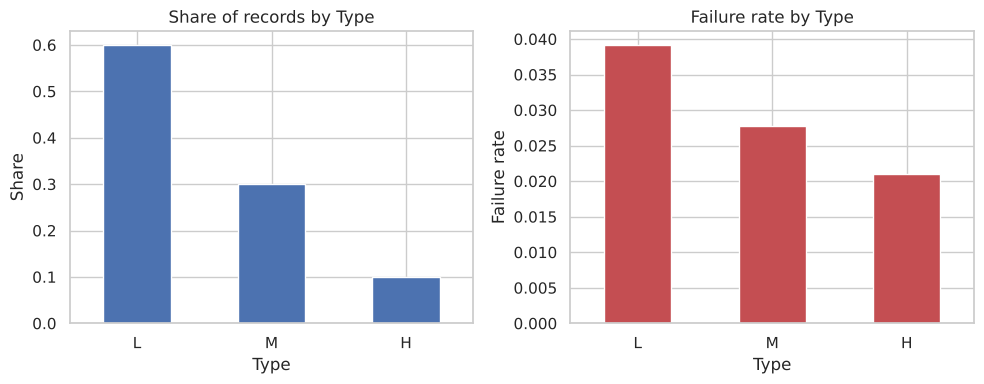

In [8]:
type_share = df["Type"].value_counts(normalize=True)
type_fail = df.groupby("Type")["Machine failure"].mean()
print("Share of records by Type:\n", type_share.round(3))
print("\nFailure rate by Type:\n", type_fail.round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
type_share.loc[["L", "M", "H"]].plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Share of records by Type"); axes[0].set_ylabel("Share")
type_fail.loc[["L", "M", "H"]].plot(kind="bar", ax=axes[1], color="#C44E52")
axes[1].set_title("Failure rate by Type"); axes[1].set_ylabel("Failure rate")
for a in axes: a.tick_params(axis="x", rotation=0)
save("03_type")

**📝 Observation:**

- Type L makes up 60% of the data, M 30% and H 10%.
- The failure rate differs by type: L 3.9% (235/6,000), M 2.8% (83/2,997) and H 2.1% (21/1,003). Lower-quality products fail more often.
- Type carries useful information, so we will keep it and one-hot encode it, and keep its proportions in every split.

## 5. Distributions of the numeric features

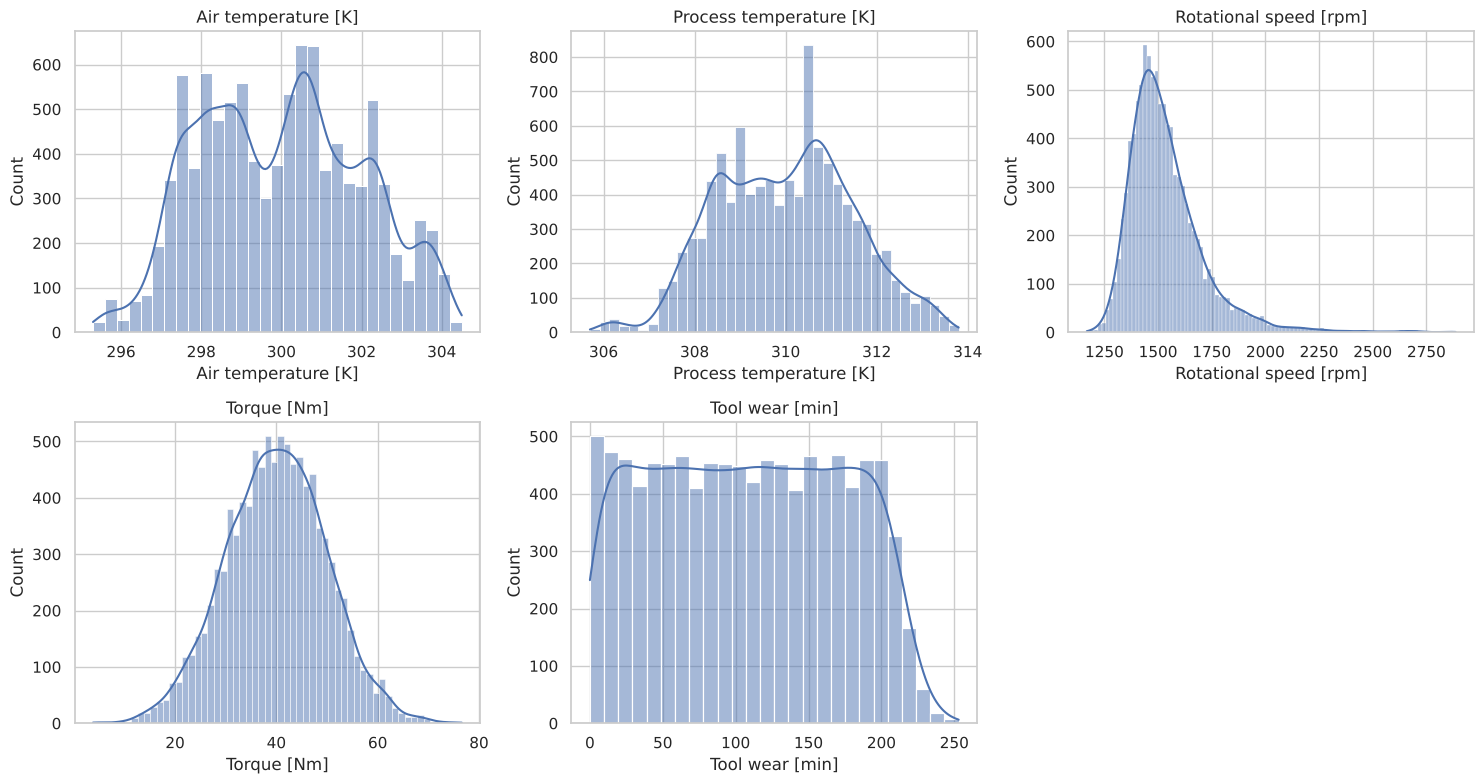

Skewness:
 Air temperature [K]        0.11
Process temperature [K]    0.02
Rotational speed [rpm]     1.99
Torque [Nm]               -0.01
Tool wear [min]            0.03
dtype: float64


In [9]:
num_cols = ["Air temperature [K]", "Process temperature [K]",
            "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="#4C72B0")
    ax.set_title(col)
axes.flat[-1].axis("off")
save("04_numeric_distributions")

print("Skewness:\n", df[num_cols].skew().round(2))

**📝 Observation:**

- Air temperature, process temperature, torque and tool wear are close to symmetric (skewness between −0.01 and 0.11). Tool wear looks roughly uniform from 0 to about 250 min.
- Rotational speed is clearly right-skewed (skewness ≈ 1.99): most values are 1,400–1,600 rpm but some reach 2,886 rpm.
- The features use very different units and ranges, so we will scale them (e.g. StandardScaler). For rotational speed, a log transform or a robust scaler can be considered. Tree-based models are not affected much by scaling, but it matters for models such as SVM or logistic regression.

## 6. Failure vs no failure: which features differ?
Features whose distributions differ clearly between the two groups are likely to be useful for the model.

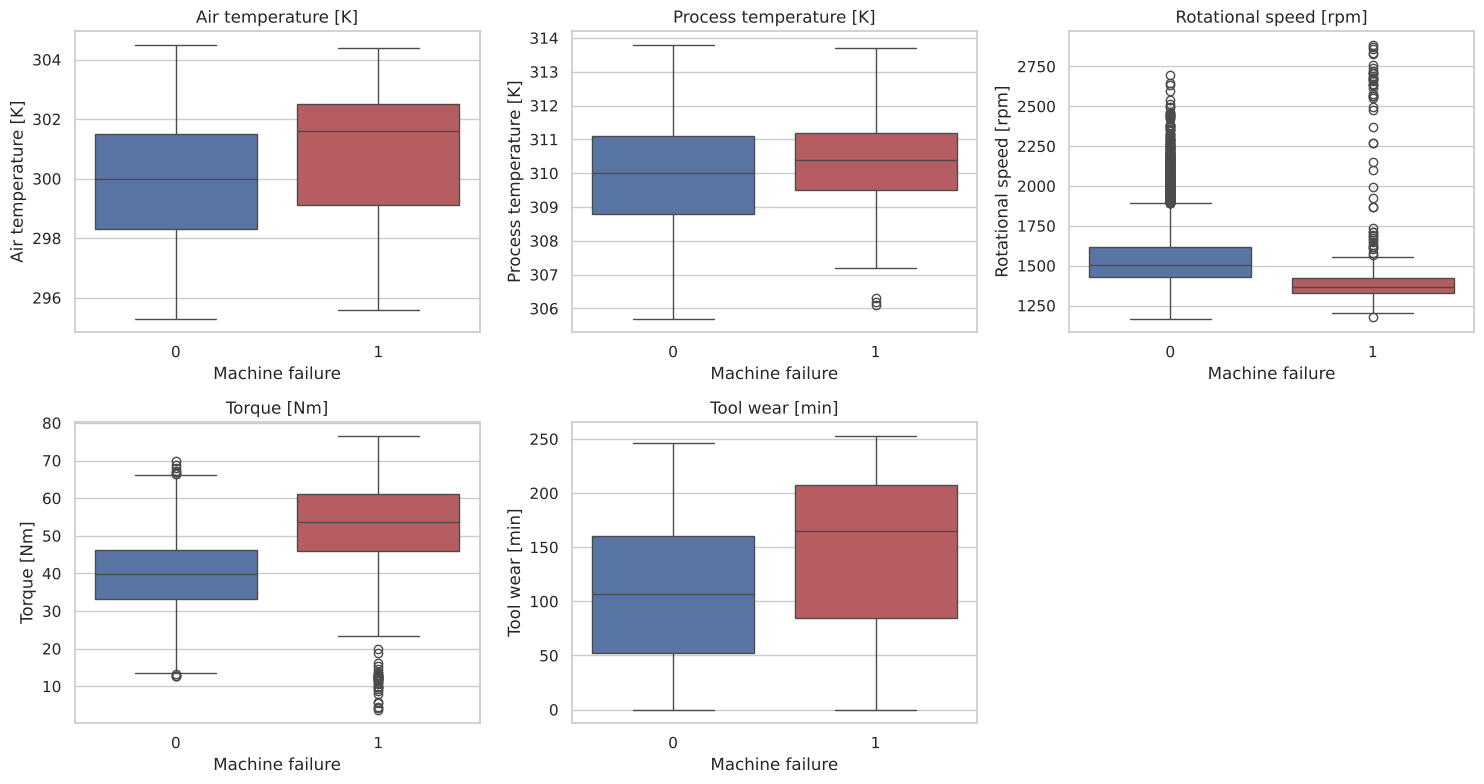

Machine failure,0,1
Air temperature [K],299.97,300.89
Process temperature [K],310.00,310.29
Rotational speed [rpm],1540.26,1496.49
Torque [Nm],39.63,50.17
Tool wear [min],106.69,143.78


In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(data=df, x="Machine failure", y=col, ax=ax,
                hue="Machine failure", palette=["#4C72B0", "#C44E52"], legend=False)
    ax.set_title(col)
axes.flat[-1].axis("off")
save("05_boxplots_by_failure")

df.groupby("Machine failure")[num_cols].mean().T.round(2)

**📝 Observation:**

- Failed machines have higher torque on average (50.2 Nm vs 39.6 Nm) and much higher tool wear (143.8 min vs 106.7 min).
- Failed machines have slightly lower rotational speed (1,497 vs 1,540 rpm) and slightly higher air temperature (300.9 vs 300.0 K).
- Torque and tool wear separate the two groups best, so they are likely to be the most important features. The overlap between the groups is still large, which suggests that combinations of features matter.

## 7. Correlation between features

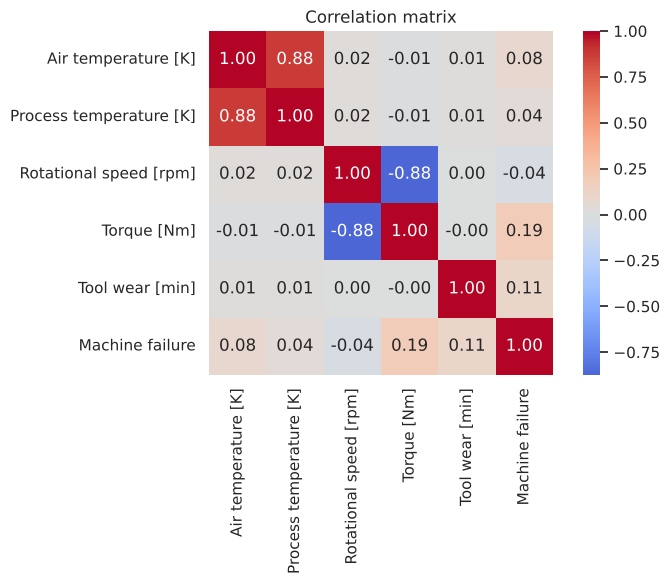

In [11]:
corr = df[num_cols + ["Machine failure"]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix")
save("06_correlation")

**📝 Observation:**

- Air temperature and process temperature are strongly correlated (0.88), and rotational speed and torque are strongly negatively correlated (−0.88). Other pairs are close to 0.
- No single feature is strongly correlated with Machine failure; the highest is torque (0.19), then tool wear (0.11).
- Failures are not explained by one feature alone, so we will create combined features (next section). The strong pairs also suggest that temperature difference and power are better summaries than the raw pairs.

## 8. Candidate engineered features
Physics-based features that match how the failure modes are defined:
- `temp_diff` = process − air temperature (heat dissipation, HDF)
- `power` = torque × rotational speed × 2π/60, in watts (power failure, PWF)
- `strain` = tool wear × torque (overstrain, OSF)

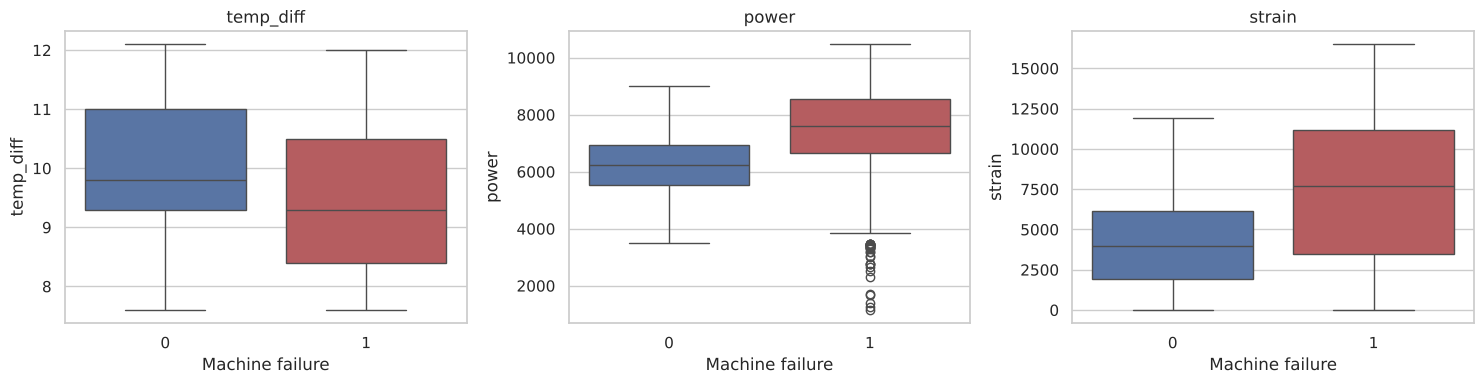

Correlation with Machine failure:
Torque [Nm]                0.191
strain                     0.190
power                      0.176
Tool wear [min]            0.105
Air temperature [K]        0.083
Process temperature [K]    0.036
Rotational speed [rpm]    -0.044
temp_diff                 -0.112
dtype: float64


In [12]:
fe = df.copy()
fe["temp_diff"] = fe["Process temperature [K]"] - fe["Air temperature [K]"]
fe["power"] = fe["Torque [Nm]"] * fe["Rotational speed [rpm]"] * 2 * np.pi / 60
fe["strain"] = fe["Tool wear [min]"] * fe["Torque [Nm]"]
new_cols = ["temp_diff", "power", "strain"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, new_cols):
    sns.boxplot(data=fe, x="Machine failure", y=col, ax=ax,
                hue="Machine failure", palette=["#4C72B0", "#C44E52"], legend=False)
    ax.set_title(col)
save("07_engineered_features")

print("Correlation with Machine failure:")
print(fe[num_cols + new_cols].corrwith(fe["Machine failure"]).sort_values(ascending=False).round(3))

In [13]:
# Do specific failure modes line up with the engineered features?
for col, mode in [("temp_diff", "HDF"), ("power", "PWF"), ("strain", "OSF")]:
    print(f"{col} – mean when {mode}=1: {fe.loc[fe[mode]==1, col].mean():.1f} | when {mode}=0: {fe.loc[fe[mode]==0, col].mean():.1f}")

temp_diff – mean when HDF=1: 8.2 | when HDF=0: 10.0
power – mean when PWF=1: 7251.8 | when PWF=0: 6270.4
strain – mean when OSF=1: 12067.0 | when OSF=0: 4237.9


**📝 Observation:**

- strain (tool wear × torque) has a correlation of 0.19 with Machine failure, almost the same as torque, and power has 0.18 – both much higher than rotational speed (−0.04) or process temperature (0.04).
- Each engineered feature lines up with its failure mode: mean strain is 12,067 when OSF = 1 vs 4,238 otherwise; mean power is 7,252 W when PWF = 1 vs 6,270 W; mean temp_diff is 8.2 K when HDF = 1 vs 10.0 K.
- These physics-based features capture the failure mechanisms better than single raw features, so we will add temp_diff, power and strain in the feature engineering step.

## 9. Summary of insights → design decisions

| # | EDA insight (with numbers) | Design decision |
|---|---|---|
| 1 | Only 3.39% of records are failures (339 of 10,000). | Use Recall and F1 as main metrics; stratified split; class weights or SMOTE on the training set only. |
| 2 | UDI and Product ID are unique identifiers with no predictive meaning. | Drop them in preprocessing. |
| 3 | Failure-mode columns define the target; labels have small inconsistencies (9 failures with no mode, 18 RNF with no failure). | Exclude TWF/HDF/PWF/OSF/RNF from model inputs to avoid leakage; use them only for the failure-type task. |
| 4 | Failure rate differs by Type: L 3.9%, M 2.8%, H 2.1%. | Keep Type as a feature (one-hot encoded) and keep its proportions in every split. |
| 5 | Features have very different scales; rotational speed is right-skewed (skewness ≈ 2). | Scale numeric features; consider a log/robust transform for rotational speed. |
| 6 | No single feature is strongly correlated with failure (max 0.19), but strain, power and temp_diff line up with OSF, PWF and HDF. | Add the engineered features temp_diff, power and strain. |